# EV Charging Demand Prediction and Usage Pattern Analysis

## 1. Importing Required Libraries

In [2]:
# Import necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

## 2. Loading the Dataset

In [3]:
# Load the dataset

df = pd.read_csv("ChargingRecords.csv")

df.head()

,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54,2022-09-15 23:59,185,20.36
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01,2022-09-14 21:31,90,10.19
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54,2022-09-14 19:54,60,6.78
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32,2022-09-30 0:16,344,37.65
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30,2022-09-26 0:30,300,33.81


## 3. Understanding the Dataset

In [4]:
# Check the number of rows and columns

df.shape

(72856, 13)

In [5]:
# Display column names and data types

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72856 entries, 0 to 72855
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   UserID          72856 non-null  int64  
 1   ChargerID       72856 non-null  int64  
 2   ChargerCompany  72856 non-null  int64  
 3   Location        72856 non-null  object 
 4   ChargerType     72856 non-null  int64  
 5   StartDay        72856 non-null  object 
 6   StartTime       72856 non-null  object 
 7   EndDay          72856 non-null  object 
 8   EndTime         72856 non-null  object 
 9   StartDatetime   72856 non-null  object 
 10  EndDatetime     72856 non-null  object 
 11  Duration        72856 non-null  int64  
 12  Demand          72856 non-null  float64
dtypes: float64(1), int64(5), object(7)
memory usage: 7.2+ MB


In [6]:
# Check for duplicate records

df.duplicated().sum()

np.int64(13)

In [7]:
# Remove duplicate records

df = df.drop_duplicates()

# Check the number of rows after removing duplicates
df.shape

(72843, 13)

In [8]:
# Check for missing values in each column

df.isnull().sum()

UserID            0
ChargerID         0
ChargerCompany    0
Location          0
ChargerType       0
StartDay          0
StartTime         0
EndDay            0
EndTime           0
StartDatetime     0
EndDatetime       0
Duration          0
Demand            0
dtype: int64

In [9]:
# Convert date and datetime columns to proper datetime format

df["StartDatetime"] = pd.to_datetime(df["StartDatetime"])
df["EndDatetime"] = pd.to_datetime(df["EndDatetime"])
df["StartDay"] = pd.to_datetime(df["StartDay"])
df["EndDay"] = pd.to_datetime(df["EndDay"])

# Check the updated data types
df[["StartDay", "EndDay", "StartDatetime", "EndDatetime"]].dtypes

StartDay         datetime64[ns]
EndDay           datetime64[ns]
StartDatetime    datetime64[ns]
EndDatetime      datetime64[ns]
dtype: object

In [10]:
# Check for negative duration values

df[df["Duration"] < 0].shape

(17, 13)

In [11]:
# Remove records with negative duration

df = df[df["Duration"] >= 0].copy()

# Check the minimum duration after cleaning
df["Duration"].min()

0

In [12]:
# Check the summary statistics of Duration and Demand

df[["Duration", "Demand"]].describe()

,Duration,Demand
count,72826.000000,72826.000000
mean,151.222105,17.440366
std,146.416111,13.490614
min,0.000000,0.010000
25%,40.000000,7.530000
50%,112.000000,14.100000
75%,202.000000,23.200000
max,1573.000000,97.000000


## 4. Feature Engineering

In [13]:
# Extract time-based features from StartDatetime

df["Hour"] = df["StartDatetime"].dt.hour
df["DayOfWeek"] = df["StartDatetime"].dt.dayofweek
df["Month"] = df["StartDatetime"].dt.month

# Check the newly created features
df[["StartDatetime", "Hour", "DayOfWeek", "Month"]].head()

,StartDatetime,Hour,DayOfWeek,Month
0,2022-09-15 20:54:00,20,3,9
1,2022-09-14 20:01:00,20,2,9
2,2022-09-14 18:54:00,18,2,9
3,2022-09-29 18:32:00,18,3,9
4,2022-09-25 19:30:00,19,6,9


In [14]:
# Identify whether the charging session occurred on a weekend

df["IsWeekend"] = df["DayOfWeek"] >= 5

# Check the result
df[["StartDatetime", "DayOfWeek", "IsWeekend"]].head()

,StartDatetime,DayOfWeek,IsWeekend
0,2022-09-15 20:54:00,3,False
1,2022-09-14 20:01:00,2,False
2,2022-09-14 18:54:00,2,False
3,2022-09-29 18:32:00,3,False
4,2022-09-25 19:30:00,6,True


In [15]:
# Create time-of-day categories based on the charging hour

df["TimeOfDay"] = pd.cut(
    df["Hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=["Night", "Morning", "Afternoon", "Evening"]
)

# Check the result
df[["Hour", "TimeOfDay"]].head()

,Hour,TimeOfDay
0,20,Evening
1,20,Evening
2,18,Evening
3,18,Evening
4,19,Evening


In [16]:
# Check the unique values of the newly created features

print("Hour:", df["Hour"].nunique())
print("DayOfWeek:", df["DayOfWeek"].nunique())
print("Month:", df["Month"].nunique())
print("IsWeekend:", df["IsWeekend"].nunique())
print("TimeOfDay:", df["TimeOfDay"].nunique())

Hour: 24
DayOfWeek: 7
Month: 12
IsWeekend: 2
TimeOfDay: 4


## 5. Exploratory Data Analysis (EDA)

In [17]:
# Check the distribution of Demand

df["Demand"].describe()

count    72826.000000
mean        17.440366
std         13.490614
min          0.010000
25%          7.530000
50%         14.100000
75%         23.200000
max         97.000000
Name: Demand, dtype: float64

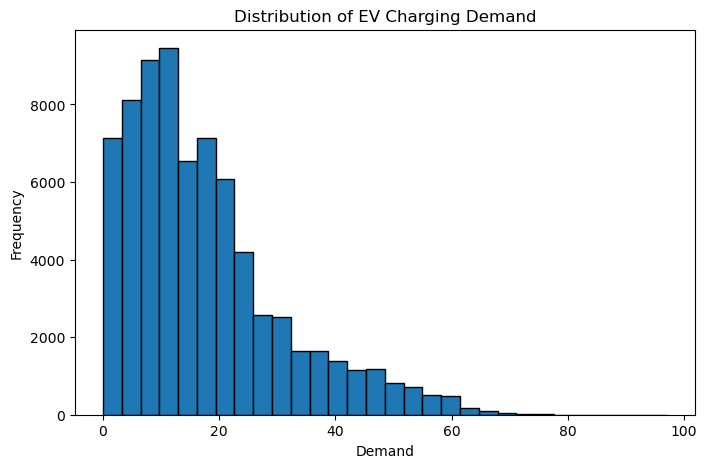

In [18]:
# Visualize the distribution of Demand

plt.figure(figsize=(8, 5))
plt.hist(df["Demand"], bins=30, edgecolor="black")

plt.xlabel("Demand")
plt.ylabel("Frequency")
plt.title("Distribution of EV Charging Demand")

plt.show()

In [19]:
# Calculate average Demand by Time of Day

df.groupby("TimeOfDay", observed=True)["Demand"].mean()

TimeOfDay
Night        23.114793
Morning      15.289768
Afternoon    14.886566
Evening      21.237800
Name: Demand, dtype: float64

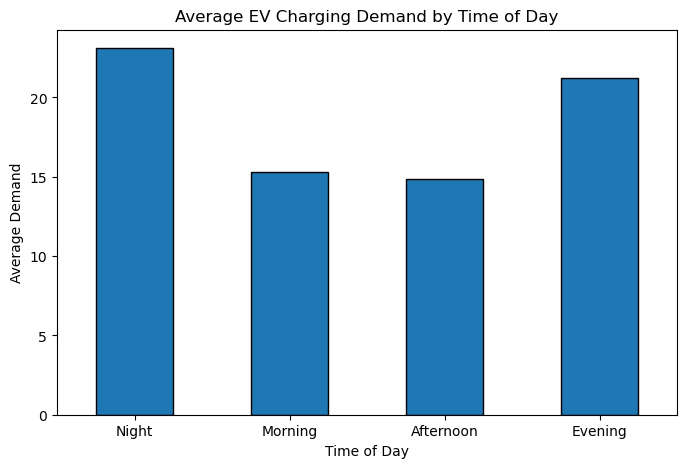

In [20]:
# Visualize average Demand by Time of Day

df.groupby("TimeOfDay", observed=True)["Demand"].mean().plot(
    kind="bar",
    figsize=(8, 5),
    edgecolor="black"
)

plt.xlabel("Time of Day")
plt.ylabel("Average Demand")
plt.title("Average EV Charging Demand by Time of Day")
plt.xticks(rotation=0)

plt.show()

In [21]:
# Calculate average Demand by Location

df.groupby("Location")["Demand"].mean().sort_values(ascending=False)

Location
accommodation         29.055829
bus garage            28.587586
camping               25.525288
apartment             18.744879
public area           17.899891
restaurant            17.813123
public institution    17.399318
resort                17.280838
public parking lot    17.187510
golf                  16.718299
market                16.506272
company               16.248039
sightseeing           15.245129
hotel                 14.702966
Name: Demand, dtype: float64

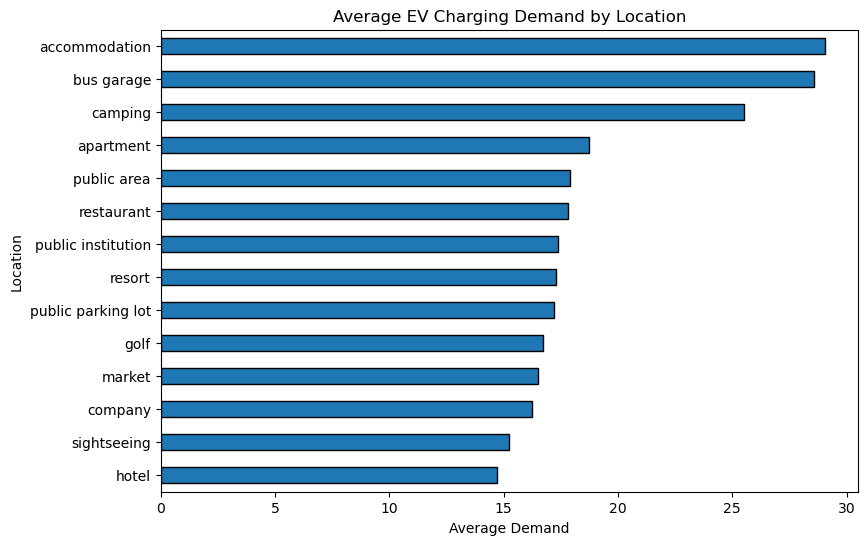

In [22]:
# Visualize average Demand by Location

location_demand = df.groupby("Location")["Demand"].mean().sort_values()

location_demand.plot(
    kind="barh",
    figsize=(9, 6),
    edgecolor="black"
)

plt.xlabel("Average Demand")
plt.ylabel("Location")
plt.title("Average EV Charging Demand by Location")

plt.show()

In [23]:
# Calculate average Demand by Charger Type

df.groupby("ChargerType")["Demand"].mean()

ChargerType
0    17.051995
1    18.946402
Name: Demand, dtype: float64

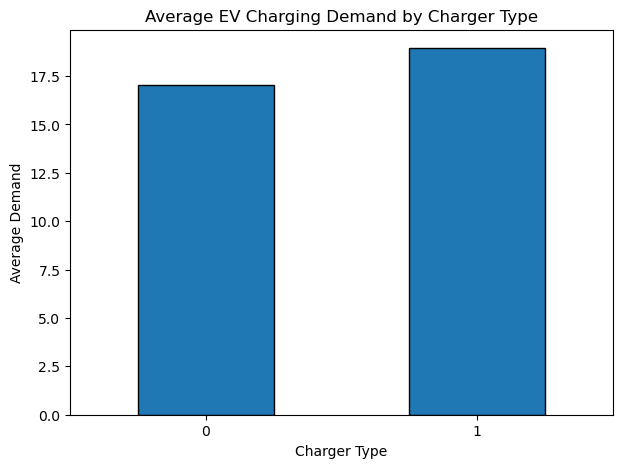

In [24]:
# Visualize average Demand by Charger Type

df.groupby("ChargerType")["Demand"].mean().plot(
    kind="bar",
    figsize=(7, 5),
    edgecolor="black"
)

plt.xlabel("Charger Type")
plt.ylabel("Average Demand")
plt.title("Average EV Charging Demand by Charger Type")
plt.xticks(rotation=0)

plt.show()

In [25]:
# Calculate average Demand for weekdays and weekends

df.groupby("IsWeekend")["Demand"].mean()

IsWeekend
False    17.384209
True     17.600308
Name: Demand, dtype: float64

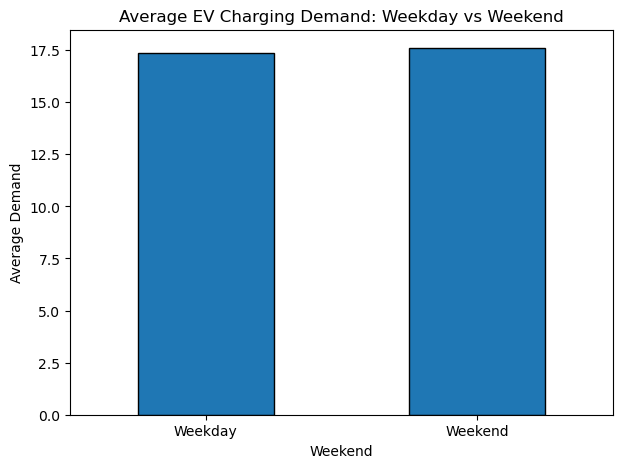

In [26]:
# Visualize average Demand by Weekend/Weekday

df.groupby("IsWeekend")["Demand"].mean().plot(
    kind="bar",
    figsize=(7, 5),
    edgecolor="black"
)

plt.xlabel("Weekend")
plt.ylabel("Average Demand")
plt.title("Average EV Charging Demand: Weekday vs Weekend")
plt.xticks([0, 1], ["Weekday", "Weekend"], rotation=0)

plt.show()

In [27]:
# Calculate average Demand for each hour

df.groupby("Hour")["Demand"].mean()

Hour
0     26.547193
1     25.319131
2     25.036850
3     20.249701
4     18.259526
5     17.245738
6     16.985157
7     16.810864
8     17.517359
9     14.408479
10    13.420777
11    13.710208
12    13.409520
13    13.703505
14    14.086236
15    14.053455
16    15.554396
17    16.987276
18    18.339424
19    20.001312
20    21.548303
21    22.847293
22    23.797213
23    27.713834
Name: Demand, dtype: float64

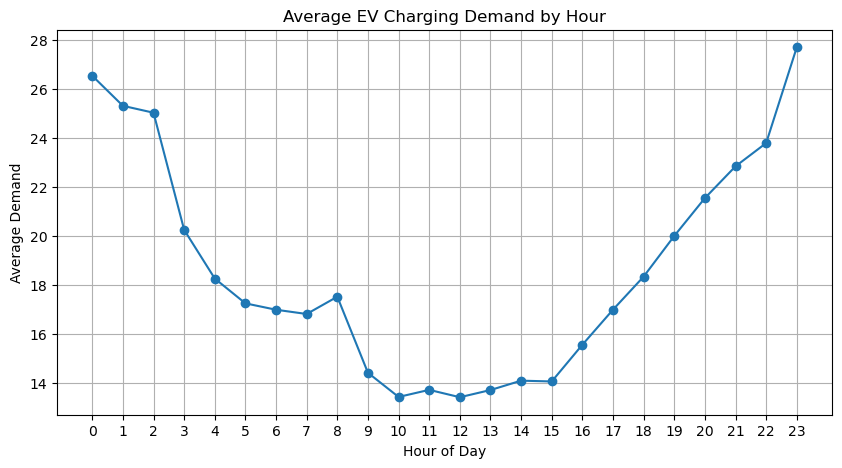

In [28]:
# Visualize average Demand by hour

hourly_demand = df.groupby("Hour")["Demand"].mean()

plt.figure(figsize=(10, 5))
plt.plot(hourly_demand.index, hourly_demand.values, marker="o")

plt.xlabel("Hour of Day")
plt.ylabel("Average Demand")
plt.title("Average EV Charging Demand by Hour")
plt.xticks(range(24))

plt.grid(True)
plt.show()

In [29]:
# Check the correlation between Duration and Demand

df[["Duration", "Demand"]].corr()

,Duration,Demand
Duration,1.000000,0.656772
Demand,0.656772,1.000000


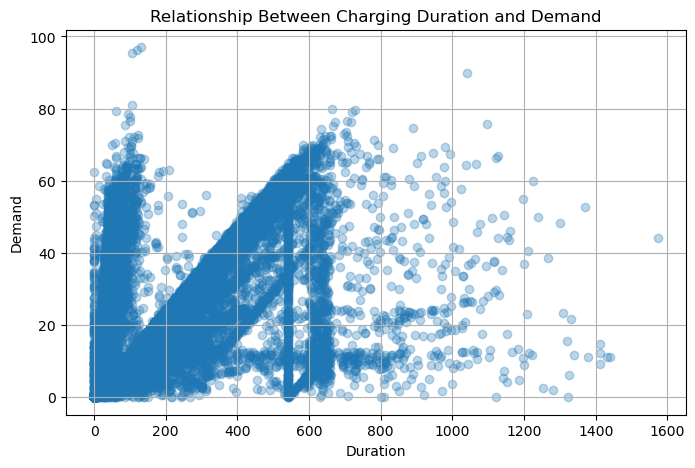

In [30]:
# Visualize the relationship between Duration and Demand

plt.figure(figsize=(8, 5))
plt.scatter(df["Duration"], df["Demand"], alpha=0.3)
plt.xlabel("Duration")
plt.ylabel("Demand")
plt.title("Relationship Between Charging Duration and Demand")
plt.grid(True)
plt.show()

In [31]:
# Calculate average demand for each location, charger type, hour and time of day

mean_demand = df.groupby(
    ["Location", "ChargerType", "Hour", "TimeOfDay"],
    observed=True
)["Demand"].mean().reset_index()

mean_demand.head()

,Location,ChargerType,Hour,TimeOfDay,Demand
0,accommodation,0,0,Night,32.796667
1,accommodation,0,1,Night,17.830000
2,accommodation,0,2,Night,6.590000
3,accommodation,0,5,Night,7.300000
4,accommodation,0,6,Morning,22.290000


In [32]:
# Check the number of unique demand groups

mean_demand.shape

(540, 5)

In [33]:
# Select features for Demand prediction

features = [
    "ChargerCompany",
    "Location",
    "ChargerType",
    "Duration",
    "Hour",
    "DayOfWeek",
    "Month",
    "IsWeekend",
    "TimeOfDay"
]

X = df[features]
y = df["Demand"]

X.head()

,ChargerCompany,Location,ChargerType,Duration,Hour,DayOfWeek,Month,IsWeekend,TimeOfDay
0,1,hotel,0,185,20,3,9,False,Evening
1,1,hotel,0,90,20,2,9,False,Evening
2,1,hotel,0,60,18,2,9,False,Evening
3,1,hotel,0,344,18,3,9,False,Evening
4,1,hotel,0,300,19,6,9,True,Evening


## 6. Regression Model

In [34]:
# Import libraries required for regression

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [35]:
# Select input features and target variable

features = [
    "ChargerCompany",
    "Location",
    "ChargerType",
    "Duration",
    "Hour",
    "DayOfWeek",
    "Month",
    "IsWeekend",
    "TimeOfDay"
]

X = df[features]
y = df["Demand"]

X.head()

,ChargerCompany,Location,ChargerType,Duration,Hour,DayOfWeek,Month,IsWeekend,TimeOfDay
0,1,hotel,0,185,20,3,9,False,Evening
1,1,hotel,0,90,20,2,9,False,Evening
2,1,hotel,0,60,18,2,9,False,Evening
3,1,hotel,0,344,18,3,9,False,Evening
4,1,hotel,0,300,19,6,9,True,Evening


In [36]:
# Convert categorical features into numerical features

X = pd.get_dummies(
    X,
    columns=["Location", "TimeOfDay"],
    drop_first=True
)

X.head()

,ChargerCompany,ChargerType,Duration,Hour,DayOfWeek,Month,IsWeekend,Location_apartment,Location_bus garage,Location_camping,...,Location_market,Location_public area,Location_public institution,Location_public parking lot,Location_resort,Location_restaurant,Location_sightseeing,TimeOfDay_Morning,TimeOfDay_Afternoon,TimeOfDay_Evening
0,1,0,185,20,3,9,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
1,1,0,90,20,2,9,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
2,1,0,60,18,2,9,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
3,1,0,344,18,3,9,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
4,1,0,300,19,6,9,True,False,False,False,...,False,False,False,False,False,False,False,False,False,True


In [37]:
# Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (58260, 23)
Testing data: (14566, 23)


### 6.1 Linear Regression

In [38]:
# Train the Linear Regression model

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Make predictions on the test data
y_pred_linear = linear_model.predict(X_test)

# Evaluate the model
mae_linear = mean_absolute_error(y_test, y_pred_linear)
mse_linear = mean_squared_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mse_linear)
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression")
print("MAE :", mae_linear)
print("MSE :", mse_linear)
print("RMSE:", rmse_linear)
print("R²  :", r2_linear)

Linear Regression
MAE : 5.607982718667048
MSE : 77.36833813593132
RMSE: 8.795927360769376
R²  : 0.5706483860734304


### 6.2 Decision Tree Regression

In [39]:
# Train the Decision Tree Regression model

tree_model = DecisionTreeRegressor(
    max_depth=10,
    random_state=42
)

tree_model.fit(X_train, y_train)

# Make predictions
y_pred_tree = tree_model.predict(X_test)

# Evaluate the model
mae_tree = mean_absolute_error(y_test, y_pred_tree)
mse_tree = mean_squared_error(y_test, y_pred_tree)
rmse_tree = np.sqrt(mse_tree)
r2_tree = r2_score(y_test, y_pred_tree)

print("Decision Tree Regression")
print("MAE :", mae_tree)
print("MSE :", mse_tree)
print("RMSE:", rmse_tree)
print("R²  :", r2_tree)

Decision Tree Regression
MAE : 3.4806361958615937
MSE : 41.938265068916934
RMSE: 6.475975993540814
R²  : 0.7672657546167801


### 6.3 Random Forest Regression

In [40]:
# Train the Random Forest Regression model

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Regression")
print("MAE :", mae_rf)
print("MSE :", mse_rf)
print("RMSE:", rmse_rf)
print("R²  :", r2_rf)

Random Forest Regression
MAE : 3.4149797156355435
MSE : 38.25386003962975
RMSE: 6.184970496261866
R²  : 0.7877121708614243


### 6.4 XGBoost Regression

In [41]:
# Import XGBoost

from xgboost import XGBRegressor

In [42]:
# Train the XGBoost Regression model

xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=6,
    random_state=42
)

xgb_model.fit(X_train, y_train)

# Make predictions
y_pred_xgb = xgb_model.predict(X_test)

# Evaluate the model
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mse_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)

print("XGBoost Regression")
print("MAE :", mae_xgb)
print("MSE :", mse_xgb)
print("RMSE:", rmse_xgb)
print("R²  :", r2_xgb)

XGBoost Regression
MAE : 3.4356183988908384
MSE : 36.610898229492406
RMSE: 6.050694028745166
R²  : 0.796829702939764


### 6.5 LightGBM Regression

In [43]:
# Import LightGBM

from lightgbm import LGBMRegressor

In [44]:
# Train the LightGBM Regression model

lgbm_model = LGBMRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=6,
    verbosity=-1,
    random_state=42
)

lgbm_model.fit(X_train, y_train)

# Make predictions
y_pred_lgbm = lgbm_model.predict(X_test)

# Evaluate the model
mae_lgbm = mean_absolute_error(y_test, y_pred_lgbm)
mse_lgbm = mean_squared_error(y_test, y_pred_lgbm)
rmse_lgbm = np.sqrt(mse_lgbm)
r2_lgbm = r2_score(y_test, y_pred_lgbm)

print("LightGBM Regression")
print("MAE :", mae_lgbm)
print("MSE :", mse_lgbm)
print("RMSE:", rmse_lgbm)
print("R²  :", r2_lgbm)

LightGBM Regression
MAE : 3.499969576231544
MSE : 37.50630161618003
RMSE: 6.124238860150707
R²  : 0.7918607078902101


### 6.6 Regression Model Comparison

In [45]:
# Compare regression models

regression_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost",
        "LightGBM"
    ],
    "MAE": [
        mae_linear,
        mae_tree,
        mae_rf,
        mae_xgb,
        mae_lgbm
    ],
    "RMSE": [
        rmse_linear,
        rmse_tree,
        rmse_rf,
        rmse_xgb,
        rmse_lgbm
    ],
    "R2": [
        r2_linear,
        r2_tree,
        r2_rf,
        r2_xgb,
        r2_lgbm
    ]
})

regression_results

,Model,MAE,RMSE,R2
0,Linear Regression,5.607983,8.795927,0.570648
1,Decision Tree,3.480636,6.475976,0.767266
2,Random Forest,3.414980,6.184970,0.787712
3,XGBoost,3.435618,6.050694,0.796830
4,LightGBM,3.499970,6.124239,0.791861


### 6.7 Regression Model Performance Comparison

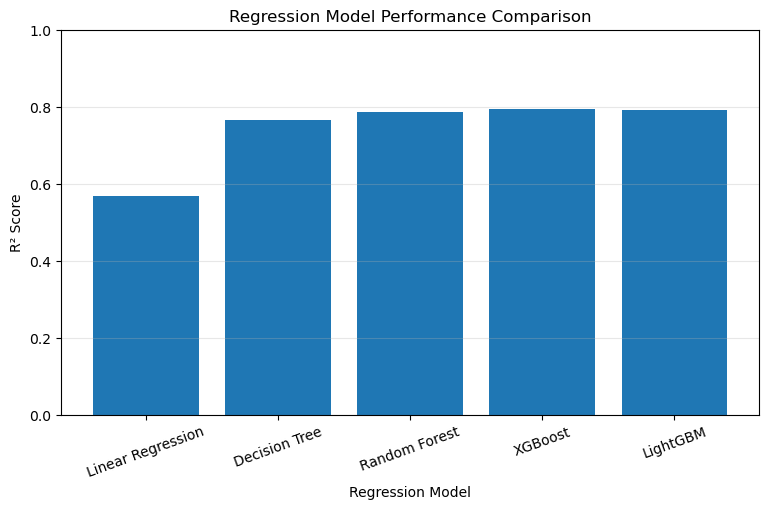

In [46]:
# Plot R² score comparison

plt.figure(figsize=(9, 5))

plt.bar(
    regression_results["Model"],
    regression_results["R2"]
)

plt.xlabel("Regression Model")
plt.ylabel("R² Score")
plt.title("Regression Model Performance Comparison")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.show()

## 7. Classification Model

### 7.1 Creating the Demand Class

In [47]:
# Create the classification target

median_demand = df["Demand"].median()

df["DemandClass"] = np.where(
    df["Demand"] >= median_demand,
    "High Demand",
    "Normal Demand"
)

print("Median Demand:", median_demand)

df[["Demand", "DemandClass"]].head()

Median Demand: 14.1


,Demand,DemandClass
0,20.36,High Demand
1,10.19,Normal Demand
2,6.78,Normal Demand
3,37.65,High Demand
4,33.81,High Demand


### 7.2 Checking Class Distribution

In [48]:
# Check the distribution of demand classes

class_counts = df["DemandClass"].value_counts()
class_percentages = df["DemandClass"].value_counts(normalize=True) * 100

print("Class Counts:")
print(class_counts)

print("\nClass Percentages:")
print(class_percentages.round(2))

Class Counts:
DemandClass
High Demand      36439
Normal Demand    36387
Name: count, dtype: int64

Class Percentages:
DemandClass
High Demand      50.04
Normal Demand    49.96
Name: proportion, dtype: float64


### 7.3 Preparing Features and Target

In [49]:
# Prepare features and target for classification

X_class = df[features].copy()
y_class = df["DemandClass"]

# Convert categorical features into numerical features
X_class = pd.get_dummies(
    X_class,
    columns=["Location", "TimeOfDay"],
    drop_first=True
)

print("Feature shape:", X_class.shape)
print("Target shape:", y_class.shape)

Feature shape: (72826, 23)
Target shape: (72826,)


### 7.4 Encoding the Target Variable

In [50]:
# Encode the target classes

y_class = y_class.map({
    "Normal Demand": 0,
    "High Demand": 1
})

print(y_class.value_counts())
print("\nTarget values:", y_class.unique())

DemandClass
1    36439
0    36387
Name: count, dtype: int64

Target values: [1 0]


### 7.5 Train-Test Split

In [51]:
# Split the classification data into training and testing sets

X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

print("Training data:", X_train_class.shape)
print("Testing data:", X_test_class.shape)

Training data: (58260, 23)
Testing data: (14566, 23)


### 7.6 Logistic Regression

In [52]:
# Import classification libraries

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [53]:
# Train the Logistic Regression model

log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_class, y_train_class)

# Make predictions
y_pred_log = log_model.predict(X_test_class)

# Evaluate the model
print("Logistic Regression")
print("Accuracy :", accuracy_score(y_test_class, y_pred_log))
print("Precision:", precision_score(y_test_class, y_pred_log))
print("Recall   :", recall_score(y_test_class, y_pred_log))
print("F1 Score :", f1_score(y_test_class, y_pred_log))
print("ROC-AUC  :", roc_auc_score(
    y_test_class,
    log_model.predict_proba(X_test_class)[:, 1]
))

Logistic Regression
Accuracy : 0.8463545242345187
Precision: 0.8294624217118998
Recall   : 0.8722557628979144
F1 Score : 0.8503210272873194
ROC-AUC  : 0.9149524799789088


### 7.7 Decision Tree Classifier

In [54]:
# Train the Decision Tree Classifier

dt_model = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

dt_model.fit(X_train_class, y_train_class)

# Make predictions
y_pred_dt = dt_model.predict(X_test_class)

# Evaluate the model
print("Decision Tree Classifier")
print("Accuracy :", accuracy_score(y_test_class, y_pred_dt))
print("Precision:", precision_score(y_test_class, y_pred_dt))
print("Recall   :", recall_score(y_test_class, y_pred_dt))
print("F1 Score :", f1_score(y_test_class, y_pred_dt))
print("ROC-AUC  :", roc_auc_score(
    y_test_class,
    dt_model.predict_proba(X_test_class)[:, 1]
))

Decision Tree Classifier
Accuracy : 0.8933131951119044
Precision: 0.868603754178452
Recall   : 0.9270032930845225
F1 Score : 0.8968538430904023
ROC-AUC  : 0.9456188865501161


### 7.8 Random Forest Classifier

In [55]:
# Train the Random Forest Classifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_class, y_train_class)

# Make predictions
y_pred_rf = rf_model.predict(X_test_class)

# Evaluate the model
print("Random Forest Classifier")
print("Accuracy :", accuracy_score(y_test_class, y_pred_rf))
print("Precision:", precision_score(y_test_class, y_pred_rf))
print("Recall   :", recall_score(y_test_class, y_pred_rf))
print("F1 Score :", f1_score(y_test_class, y_pred_rf))
print("ROC-AUC  :", roc_auc_score(
    y_test_class,
    rf_model.predict_proba(X_test_class)[:, 1]
))

Random Forest Classifier
Accuracy : 0.891940134559934
Precision: 0.8785108638049814
Recall   : 0.9098518111964874
F1 Score : 0.8939067133998382
ROC-AUC  : 0.9535959894019208


### 7.9 K-Nearest Neighbors (KNN) Classifier

In [56]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Create the KNN pipeline
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# Train the model
knn_model.fit(X_train_class, y_train_class)

# Make predictions
y_pred_knn = knn_model.predict(X_test_class)

# Evaluate the model
print("K-Nearest Neighbors (KNN) Classifier")
print("Accuracy :", accuracy_score(y_test_class, y_pred_knn))
print("Precision:", precision_score(y_test_class, y_pred_knn))
print("Recall   :", recall_score(y_test_class, y_pred_knn))
print("F1 Score :", f1_score(y_test_class, y_pred_knn))
print("ROC-AUC  :", roc_auc_score(
    y_test_class,
    knn_model.predict_proba(X_test_class)[:, 1]
))

K-Nearest Neighbors (KNN) Classifier
Accuracy : 0.8402444047782507
Precision: 0.8296345514950166
Recall   : 0.8566136114160263
F1 Score : 0.842908256261392
ROC-AUC  : 0.9111283169523721


### 7.10 Support Vector Machine (SVM) Classifier

In [57]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

svm_model = make_pipeline(
    StandardScaler(),
    LinearSVC(max_iter=5000, random_state=42)
)

svm_model.fit(X_train_class, y_train_class)

y_pred_svm = svm_model.predict(X_test_class)
y_score_svm = svm_model.decision_function(X_test_class)

print("SVM Classification Results")
print("Accuracy:", accuracy_score(y_test_class, y_pred_svm))
print("Precision:", precision_score(y_test_class, y_pred_svm))
print("Recall:", recall_score(y_test_class, y_pred_svm))
print("F1 Score:", f1_score(y_test_class, y_pred_svm))
print("ROC-AUC:", roc_auc_score(y_test_class, y_score_svm))


SVM Classification Results
Accuracy: 0.8134010709872306
Precision: 0.8028094354624967
Recall: 0.8312294182217344
F1 Score: 0.8167722798975326
ROC-AUC: 0.8963371975871829


### 7.11 XGBoost Classification

In [58]:

from xgboost import XGBClassifier

xgb_classifier = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

xgb_classifier.fit(X_train_class, y_train_class)

y_pred_xgb = xgb_classifier.predict(X_test_class)
y_score_xgb = xgb_classifier.predict_proba(X_test_class)[:, 1]

print("XGBoost Classification Results")
print("Accuracy:", accuracy_score(y_test_class, y_pred_xgb))
print("Precision:", precision_score(y_test_class, y_pred_xgb))
print("Recall:", recall_score(y_test_class, y_pred_xgb))
print("F1 Score:", f1_score(y_test_class, y_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_test_class, y_score_xgb))


XGBoost Classification Results
Accuracy: 0.8968144995194288
Precision: 0.8708808821643801
Recall: 0.9319429198682766
F1 Score: 0.900377808709485
ROC-AUC: 0.9607272918338925


### 7.12 LightGBM

In [59]:

from lightgbm import LGBMClassifier

lgbm_classifier = LGBMClassifier(
    n_estimators=100,
    max_depth=-1,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgbm_classifier.fit(X_train_class, y_train_class)

y_pred_lgbm = lgbm_classifier.predict(X_test_class)
y_score_lgbm = lgbm_classifier.predict_proba(X_test_class)[:, 1]

print("LightGBM Classification Results")
print("Accuracy:", accuracy_score(y_test_class, y_pred_lgbm))
print("Precision:", precision_score(y_test_class, y_pred_lgbm))
print("Recall:", recall_score(y_test_class, y_pred_lgbm))
print("F1 Score:", f1_score(y_test_class, y_pred_lgbm))
print("ROC-AUC:", roc_auc_score(y_test_class, y_score_lgbm))


LightGBM Classification Results
Accuracy: 0.8968144995194288
Precision: 0.871930050147872
Recall: 0.9304335894621295
F1 Score: 0.9002323265847992
ROC-AUC: 0.9605932095704269


### Step 1 — Extract feature importance

In [60]:

import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "Feature": X_train_class.columns,
    "Importance": xgb_classifier.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

print("Top 10 Features Influencing EV Charging Demand:")
print(feature_importance.head(10))


Top 10 Features Influencing EV Charging Demand:
                 Feature  Importance
1            ChargerType    0.647194
2               Duration    0.117529
0         ChargerCompany    0.089792
17       Location_resort    0.021408
10      Location_company    0.012298
13       Location_market    0.011413
12        Location_hotel    0.010618
14  Location_public area    0.009879
7     Location_apartment    0.009651
9       Location_camping    0.009295


### Step 2 — Visualize the top 10 features

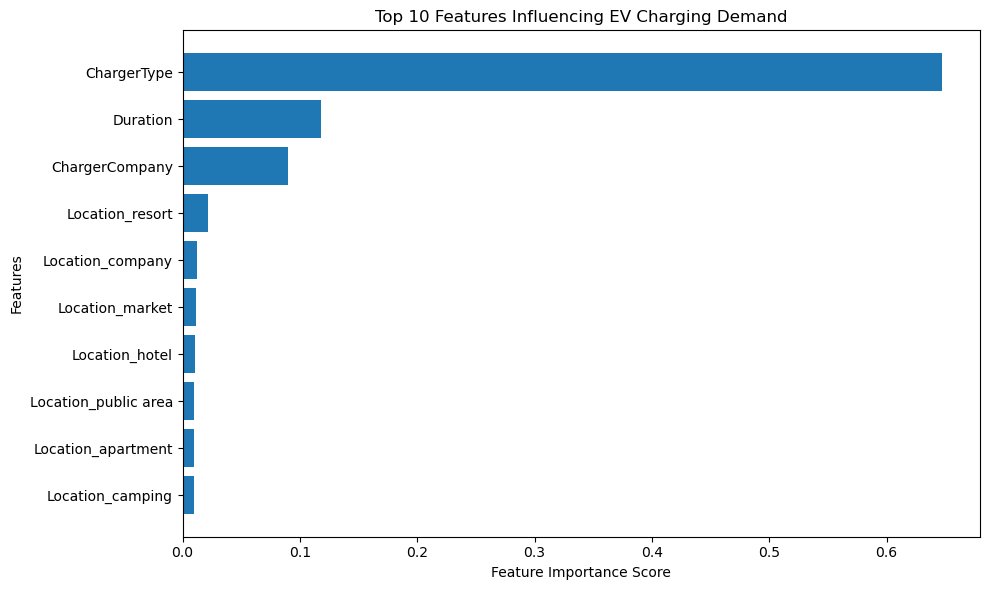

In [61]:

top_10_features = feature_importance.head(10).sort_values(
    by="Importance", ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_10_features["Feature"],
    top_10_features["Importance"]
)

plt.title("Top 10 Features Influencing EV Charging Demand")
plt.xlabel("Feature Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


### Step 3 — Confusion Matrix

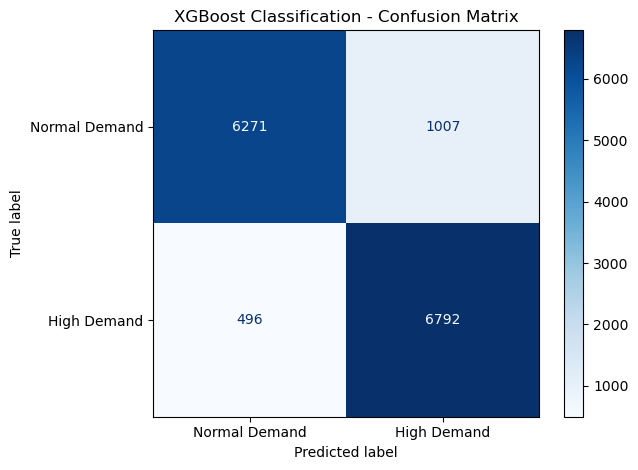

In [62]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test_class, y_pred_xgb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal Demand", "High Demand"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("XGBoost Classification - Confusion Matrix")
plt.tight_layout()
plt.show()


### Step 4 — Save the best classification model

In [63]:

import pickle

with open("ev_charging_xgb_classifier.pkl", "wb") as file:
    pickle.dump(xgb_classifier, file)

print("XGBoost classification model saved successfully!")


XGBoost classification model saved successfully!


### Step 5 — Save feature information

In [64]:

with open("ev_charging_feature_columns.pkl", "wb") as file:
    pickle.dump(list(X_train_class.columns), file)

print("Feature columns saved successfully!")
print("Total features:", len(X_train_class.columns))


Feature columns saved successfully!
Total features: 23


### Step 6 — Create the comparison table

In [65]:

classification_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.84635,
        "Precision": 0.82946,
        "Recall": 0.87226,
        "F1 Score": 0.85032,
        "ROC-AUC": 0.91495
    },
    {
        "Model": "Decision Tree",
        "Accuracy": 0.89331,
        "Precision": 0.86860,
        "Recall": 0.92700,
        "F1 Score": 0.89685,
        "ROC-AUC": 0.94562
    },
    {
        "Model": "Random Forest",
        "Accuracy": 0.89194,
        "Precision": 0.87851,
        "Recall": 0.90985,
        "F1 Score": 0.89391,
        "ROC-AUC": 0.95360
    },
    {
        "Model": "KNN",
        "Accuracy": 0.84024,
        "Precision": 0.82963,
        "Recall": 0.85661,
        "F1 Score": 0.84291,
        "ROC-AUC": 0.91113
    },
    {
        "Model": "Linear SVM",
        "Accuracy": 0.81340,
        "Precision": 0.80281,
        "Recall": 0.83123,
        "F1 Score": 0.81677,
        "ROC-AUC": 0.89634
    },
    {
        "Model": "XGBoost",
        "Accuracy": 0.89681,
        "Precision": 0.87088,
        "Recall": 0.93194,
        "F1 Score": 0.90038,
        "ROC-AUC": 0.96073
    },
    {
        "Model": "LightGBM",
        "Accuracy": 0.89681,
        "Precision": 0.87193,
        "Recall": 0.93043,
        "F1 Score": 0.90023,
        "ROC-AUC": 0.96059
    }
])

display(
    classification_results.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}",
        "ROC-AUC": "{:.2%}"
    })
)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,84.64%,82.95%,87.23%,85.03%,91.50%
1,Decision Tree,89.33%,86.86%,92.70%,89.69%,94.56%
2,Random Forest,89.19%,87.85%,90.98%,89.39%,95.36%
3,KNN,84.02%,82.96%,85.66%,84.29%,91.11%
4,Linear SVM,81.34%,80.28%,83.12%,81.68%,89.63%
5,XGBoost,89.68%,87.09%,93.19%,90.04%,96.07%
6,LightGBM,89.68%,87.19%,93.04%,90.02%,96.06%


### Save the comparison table

In [66]:

classification_results.to_csv(
    "ev_charging_classification_comparison.csv",
    index=False
)

print("Classification comparison table saved successfully!")


Classification comparison table saved successfully!


### Regression model comparison

In [67]:

regression_results = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MAE": 5.608,
        "RMSE": 8.796,
        "R2 Score": 0.571
    },
    {
        "Model": "Decision Tree",
        "MAE": 3.481,
        "RMSE": 6.476,
        "R2 Score": 0.767
    },
    {
        "Model": "Random Forest",
        "MAE": 3.415,
        "RMSE": 6.185,
        "R2 Score": 0.788
    },
    {
        "Model": "XGBoost",
        "MAE": 3.436,
        "RMSE": 6.051,
        "R2 Score": 0.797
    },
    {
        "Model": "LightGBM",
        "MAE": 3.500,
        "RMSE": 6.124,
        "R2 Score": 0.792
    }
])

display(regression_results)

regression_results.to_csv(
    "ev_charging_regression_comparison.csv",
    index=False
)

print("Regression comparison table saved successfully!")


regression_results = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MAE": 5.608,
        "RMSE": 8.796,
        "R2 Score": 0.571
    },
    {
        "Model": "Decision Tree",
        "MAE": 3.481,
        "RMSE": 6.476,
        "R2 Score": 0.767
    },
    {
        "Model": "Random Forest",
        "MAE": 3.415,
        "RMSE": 6.185,
        "R2 Score": 0.788
    },
    {
        "Model": "XGBoost",
        "MAE": 3.436,
        "RMSE": 6.051,
        "R2 Score": 0.797
    },
    {
        "Model": "LightGBM",
        "MAE": 3.500,
        "RMSE": 6.124,
        "R2 Score": 0.792
    }
])

display(regression_results)

regression_results.to_csv(
    "ev_charging_regression_comparison.csv",
    index=False
)

print("Regression comparison table saved successfully!")


,Model,MAE,RMSE,R2 Score
0,Linear Regression,5.608,8.796,0.571
1,Decision Tree,3.481,6.476,0.767
2,Random Forest,3.415,6.185,0.788
3,XGBoost,3.436,6.051,0.797
4,LightGBM,3.500,6.124,0.792


Regression comparison table saved successfully!


,Model,MAE,RMSE,R2 Score
0,Linear Regression,5.608,8.796,0.571
1,Decision Tree,3.481,6.476,0.767
2,Random Forest,3.415,6.185,0.788
3,XGBoost,3.436,6.051,0.797
4,LightGBM,3.500,6.124,0.792


Regression comparison table saved successfully!


### Save the best regression model

In [68]:

import pickle

with open("ev_charging_xgb_regressor.pkl", "wb") as file:
    pickle.dump(xgb_model, file)

print("XGBoost regression model saved successfully!")


XGBoost regression model saved successfully!


### Step 1: Install SHAP

In [69]:

%pip install shap


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


### Step 2: Import SHAP and explain our model

In [70]:

import shap

print("SHAP version:", shap.__version__)
print("XGBoost model:", type(xgb_classifier).__name__)


SHAP version: 0.53.0
XGBoost model: XGBClassifier


### Step 3: Create the SHAP explainer

In [71]:

explainer = shap.TreeExplainer(xgb_classifier)

print("SHAP explainer created successfully!")


SHAP explainer created successfully!


### Step 4: Calculate SHAP values

In [72]:

X_shap = X_test_class.sample(
    n=min(500, len(X_test_class)),
    random_state=42
)

shap_values = explainer(X_shap)

print("SHAP values calculated successfully!")
print("Sample shape:", X_shap.shape)


SHAP values calculated successfully!
Sample shape: (500, 23)


### Step 5: Generate the SHAP summary plot

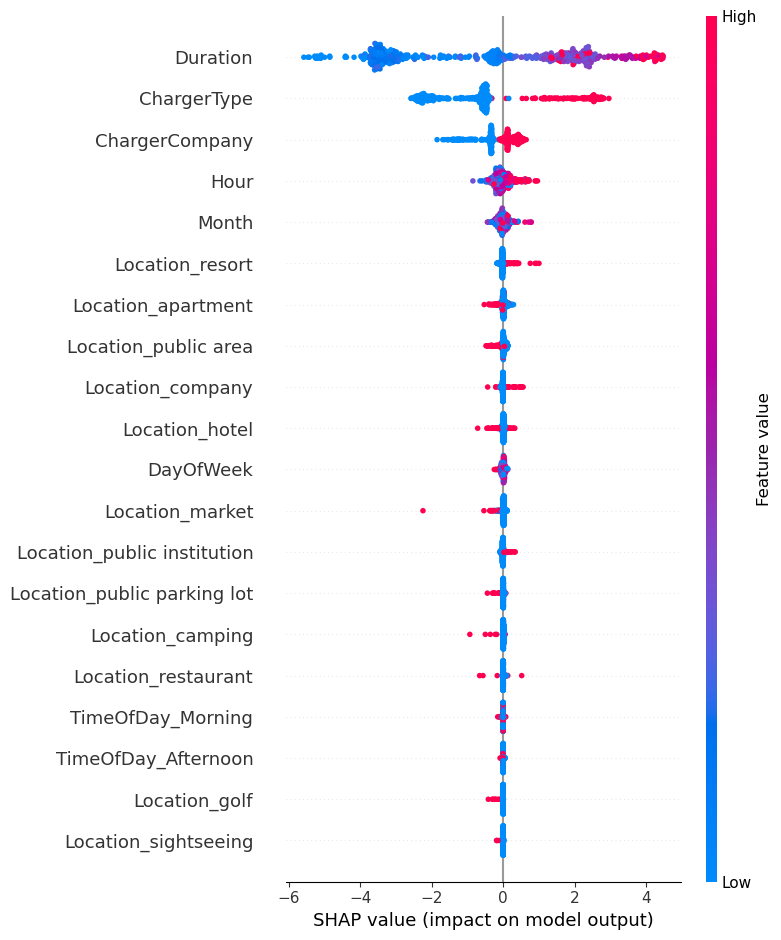

In [73]:

shap.summary_plot(shap_values, X_shap)


### Step 6: Save the SHAP plot

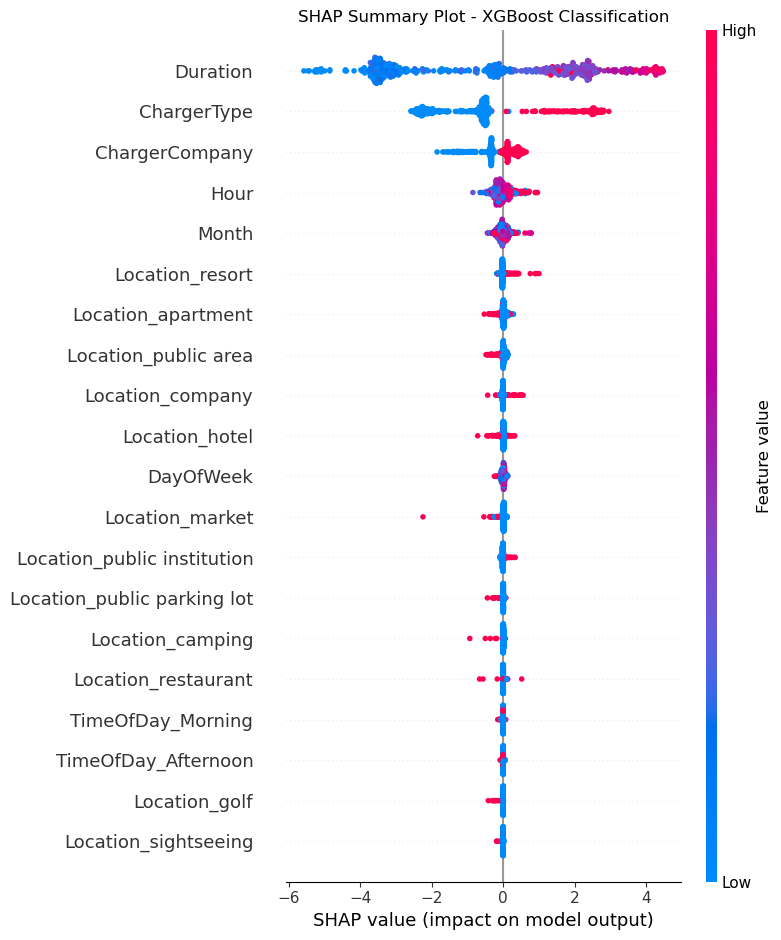

SHAP summary plot saved successfully!


In [74]:

import matplotlib.pyplot as plt

shap.summary_plot(shap_values, X_shap, show=False)
plt.title("SHAP Summary Plot - XGBoost Classification")
plt.tight_layout()
plt.savefig("ev_charging_shap_summary.png", dpi=300, bbox_inches="tight")
plt.show()

print("SHAP summary plot saved successfully!")


In [75]:

import os

print("Current folder:", os.getcwd())

files_to_check = [
    "ev_charging_xgb_classifier.pkl",
    "ev_charging_xgb_regressor.pkl",
    "ev_charging_feature_columns.pkl"
]

for file in files_to_check:
    print(file, "->", "Found" if os.path.exists(file) else "Not found")


Current folder: C:\Users\Lenovo
ev_charging_xgb_classifier.pkl -> Found
ev_charging_xgb_regressor.pkl -> Found
ev_charging_feature_columns.pkl -> Found


## Create the Streamlit dashboard file

In [76]:

dashboard_file = "ev_charging_dashboard.py"

with open(dashboard_file, "w", encoding="utf-8") as file:
    file.write("# EV Charging Demand Prediction Dashboard\n")

print("Dashboard file created:", os.path.abspath(dashboard_file))


Dashboard file created: C:\Users\Lenovo\ev_charging_dashboard.py


### Add the dashboard imports and load our saved models

In [77]:

dashboard_code = '''
import streamlit as st
import pandas as pd
import numpy as np
import pickle
import os

st.set_page_config(
    page_title="EV Charging Demand Prediction",
    page_icon="⚡",
    layout="wide"
)

st.title("⚡ EV Charging Demand Prediction")
st.write("Predict EV charging demand and explore usage patterns.")

@st.cache_resource
def load_models():
    with open("ev_charging_xgb_classifier.pkl", "rb") as file:
        classifier = pickle.load(file)

    with open("ev_charging_xgb_regressor.pkl", "rb") as file:
        regressor = pickle.load(file)

    with open("ev_charging_feature_columns.pkl", "rb") as file:
        feature_columns = pickle.load(file)

    return classifier, regressor, feature_columns

st.success("Dashboard interface initialized!")
'''

with open("ev_charging_dashboard.py", "w", encoding="utf-8") as file:
    file.write(dashboard_code)

print("Dashboard imports and model-loading code added!")


Dashboard imports and model-loading code added!


### Check the regression model's features

In [78]:

with open("ev_charging_xgb_regressor.pkl", "rb") as file:
    regressor_check = pickle.load(file)

print("Regression model:", type(regressor_check).__name__)
print("Expected number of features:", regressor_check.n_features_in_)

if hasattr(regressor_check, "feature_names_in_"):
    print("Expected feature names:")
    print(list(regressor_check.feature_names_in_))
else:
    print("Feature names were not stored in the model.")


Regression model: XGBRegressor
Expected number of features: 23
Expected feature names:
[np.str_('ChargerCompany'), np.str_('ChargerType'), np.str_('Duration'), np.str_('Hour'), np.str_('DayOfWeek'), np.str_('Month'), np.str_('IsWeekend'), np.str_('Location_apartment'), np.str_('Location_bus garage'), np.str_('Location_camping'), np.str_('Location_company'), np.str_('Location_golf'), np.str_('Location_hotel'), np.str_('Location_market'), np.str_('Location_public area'), np.str_('Location_public institution'), np.str_('Location_public parking lot'), np.str_('Location_resort'), np.str_('Location_restaurant'), np.str_('Location_sightseeing'), np.str_('TimeOfDay_Morning'), np.str_('TimeOfDay_Afternoon'), np.str_('TimeOfDay_Evening')]


### Save the regression feature columns

In [79]:

regression_feature_columns = list(regressor_check.feature_names_in_)

with open("ev_charging_regression_feature_columns.pkl", "wb") as file:
    pickle.dump(regression_feature_columns, file)

print("Regression feature columns saved successfully!")
print("Total features:", len(regression_feature_columns))


Regression feature columns saved successfully!
Total features: 23


### Update the dashboard model loader

In [80]:

dashboard_code = '''
import streamlit as st
import pandas as pd
import numpy as np
import pickle

st.set_page_config(
    page_title="EV Charging Demand Prediction",
    page_icon="⚡",
    layout="wide"
)

st.title("⚡ EV Charging Demand Prediction")
st.write("Predict EV charging demand and explore charging patterns.")

@st.cache_resource
def load_models():
    with open("ev_charging_xgb_classifier.pkl", "rb") as file:
        classifier = pickle.load(file)

    with open("ev_charging_xgb_regressor.pkl", "rb") as file:
        regressor = pickle.load(file)

    with open("ev_charging_feature_columns.pkl", "rb") as file:
        classifier_features = pickle.load(file)

    with open("ev_charging_regression_feature_columns.pkl", "rb") as file:
        regression_features = pickle.load(file)

    return classifier, regressor, classifier_features, regression_features

classifier, regressor, classifier_features, regression_features = load_models()

st.success("Both trained models loaded successfully!")

tab1, tab2 = st.tabs(["Demand Classification", "Demand Prediction"])

with tab1:
    st.subheader("High or Normal Demand")
    st.write("Enter charging session details to classify demand.")

with tab2:
    st.subheader("Predicted Charging Demand")
    st.write("Enter charging session details to estimate demand.")
'''

with open("ev_charging_dashboard.py", "w", encoding="utf-8") as file:
    file.write(dashboard_code)

print("Dashboard model loader updated successfully!")


Dashboard model loader updated successfully!


### Add the charging-session input fields

In [81]:

dashboard_code = '''
import streamlit as st
import pandas as pd
import numpy as np
import pickle

st.set_page_config(page_title="EV Charging Demand Prediction", page_icon="⚡", layout="wide")
st.title("⚡ EV Charging Demand Prediction")
st.write("Predict EV charging demand and explore charging patterns.")

@st.cache_resource
def load_models():
    with open("ev_charging_xgb_classifier.pkl", "rb") as f:
        classifier = pickle.load(f)
    with open("ev_charging_xgb_regressor.pkl", "rb") as f:
        regressor = pickle.load(f)
    with open("ev_charging_feature_columns.pkl", "rb") as f:
        classifier_features = pickle.load(f)
    with open("ev_charging_regression_feature_columns.pkl", "rb") as f:
        regression_features = pickle.load(f)
    return classifier, regressor, classifier_features, regression_features

classifier, regressor, classifier_features, regression_features = load_models()

st.success("Both trained models loaded successfully!")

def charging_inputs(prefix):
    st.subheader("Charging Session Details")
    company = st.selectbox("Charger Company", ["ChargePoint", "Other"], key=f"{prefix}_company")
    location = st.selectbox(
        "Location",
        ["apartment", "bus garage", "camping", "company", "golf", "hotel",
         "market", "public area", "public institution", "public parking lot",
         "resort", "restaurant", "sightseeing"],
        key=f"{prefix}_location"
    )
    charger_type = st.selectbox("Charger Type", ["AC", "DC"], key=f"{prefix}_type")
    duration = st.number_input("Charging Duration (hours)", min_value=0.01, value=1.0, step=0.25, key=f"{prefix}_duration")
    hour = st.slider("Hour of Day", 0, 23, 12, key=f"{prefix}_hour")
    day = st.selectbox("Day of Week (0=Monday, 6=Sunday)", list(range(7)), key=f"{prefix}_day")
    month = st.slider("Month", 1, 12, 6, key=f"{prefix}_month")
    weekend = st.checkbox("Is Weekend?", key=f"{prefix}_weekend")
    time_of_day = st.selectbox("Time of Day", ["Morning", "Afternoon", "Evening"], key=f"{prefix}_time")
    return {
        "ChargerCompany": company,
        "Location": location,
        "ChargerType": charger_type,
        "Duration": duration,
        "Hour": hour,
        "DayOfWeek": day,
        "Month": month,
        "IsWeekend": int(weekend),
        "TimeOfDay": time_of_day
    }

tab1, tab2 = st.tabs(["Demand Classification", "Demand Prediction"])

with tab1:
    user_input_class = charging_inputs("class")
    st.info("Input fields added. Prediction button will be enabled next.")

with tab2:
    user_input_reg = charging_inputs("reg")
    st.info("Input fields added. Prediction button will be enabled next.")
'''

with open("ev_charging_dashboard.py", "w", encoding="utf-8") as f:
    f.write(dashboard_code)

print("Charging-session input fields added successfully!")


Charging-session input fields added successfully!


### Check the actual categories in dataset

In [82]:

print("Charger Companies:")
print(sorted(df["ChargerCompany"].dropna().astype(str).unique()))

print("\nCharger Types:")
print(sorted(df["ChargerType"].dropna().astype(str).unique()))

print("\nLocations:")
print(sorted(df["Location"].dropna().astype(str).unique()))

print("\nTime of Day:")
print(sorted(df["TimeOfDay"].dropna().astype(str).unique()))


Charger Companies:
['0', '1']

Charger Types:
['0', '1']

Locations:
['accommodation', 'apartment', 'bus garage', 'camping', 'company', 'golf', 'hotel', 'market', 'public area', 'public institution', 'public parking lot', 'resort', 'restaurant', 'sightseeing']

Time of Day:
['Afternoon', 'Evening', 'Morning', 'Night']


### Check the encoded category mappings

In [83]:

print("ChargerCompany mapping:")
print(df.groupby("ChargerCompany")["ChargerCompany"].count())

print("\nOriginal ChargerCompany values, if available:")
print(df["ChargerCompany"].value_counts())

print("\nChargerType mapping:")
print(df["ChargerType"].value_counts())

print("\nSample records:")
display(df[["ChargerCompany", "ChargerType", "Location", "TimeOfDay"]].head(10))


ChargerCompany mapping:
ChargerCompany
0    27117
1    45709
Name: ChargerCompany, dtype: int64

Original ChargerCompany values, if available:
ChargerCompany
1    45709
0    27117
Name: count, dtype: int64

ChargerType mapping:
ChargerType
0    57896
1    14930
Name: count, dtype: int64

Sample records:


,ChargerCompany,ChargerType,Location,TimeOfDay
0,1,0,hotel,Evening
1,1,0,hotel,Evening
2,1,0,hotel,Evening
3,1,0,hotel,Evening
4,1,0,hotel,Evening
5,1,0,hotel,Afternoon
6,1,0,hotel,Evening
7,1,0,hotel,Evening
8,1,0,hotel,Evening
9,1,0,hotel,Evening


### Update the dashboard categories

In [84]:

dashboard_path = os.path.abspath("ev_charging_dashboard.py")

with open(dashboard_path, "r", encoding="utf-8") as file:
    dashboard_code = file.read()

dashboard_code = dashboard_code.replace(
    '["ChargePoint", "Other"]',
    '["0", "1"]'
)

dashboard_code = dashboard_code.replace(
    '["apartment", "bus garage", "camping", "company", "golf", "hotel",\n         "market", "public area", "public institution", "public parking lot",\n         "resort", "restaurant", "sightseeing"]',
    '["accommodation", "apartment", "bus garage", "camping", "company", "golf",\n         "hotel", "market", "public area", "public institution",\n         "public parking lot", "resort", "restaurant", "sightseeing"]'
)

dashboard_code = dashboard_code.replace(
    '["AC", "DC"]',
    '["0", "1"]'
)

dashboard_code = dashboard_code.replace(
    '["Morning", "Afternoon", "Evening"]',
    '["Morning", "Afternoon", "Evening", "Night"]'
)

with open(dashboard_path, "w", encoding="utf-8") as file:
    file.write(dashboard_code)

print("Dashboard category options updated!")


Dashboard category options updated!


In [85]:
import pickle

with open("ev_charging_xgb_classifier.pkl", "rb") as f:
    classifier_check = pickle.load(f)

with open("ev_charging_xgb_regressor.pkl", "rb") as f:
    regressor_check = pickle.load(f)

print("Classification features:")
print(classifier_check.feature_names_in_.tolist())

print("\nRegression features:")
print(regressor_check.feature_names_in_.tolist())

Classification features:
['ChargerCompany', 'ChargerType', 'Duration', 'Hour', 'DayOfWeek', 'Month', 'IsWeekend', 'Location_apartment', 'Location_bus garage', 'Location_camping', 'Location_company', 'Location_golf', 'Location_hotel', 'Location_market', 'Location_public area', 'Location_public institution', 'Location_public parking lot', 'Location_resort', 'Location_restaurant', 'Location_sightseeing', 'TimeOfDay_Morning', 'TimeOfDay_Afternoon', 'TimeOfDay_Evening']

Regression features:
['ChargerCompany', 'ChargerType', 'Duration', 'Hour', 'DayOfWeek', 'Month', 'IsWeekend', 'Location_apartment', 'Location_bus garage', 'Location_camping', 'Location_company', 'Location_golf', 'Location_hotel', 'Location_market', 'Location_public area', 'Location_public institution', 'Location_public parking lot', 'Location_resort', 'Location_restaurant', 'Location_sightseeing', 'TimeOfDay_Morning', 'TimeOfDay_Afternoon', 'TimeOfDay_Evening']


### Verify both models' feature columns

In [86]:

print("Classification features:")
print(classifier_check.feature_names_in_.tolist())

print("\nRegression features:")
print(regressor_check.feature_names_in_.tolist())

Classification features:
['ChargerCompany', 'ChargerType', 'Duration', 'Hour', 'DayOfWeek', 'Month', 'IsWeekend', 'Location_apartment', 'Location_bus garage', 'Location_camping', 'Location_company', 'Location_golf', 'Location_hotel', 'Location_market', 'Location_public area', 'Location_public institution', 'Location_public parking lot', 'Location_resort', 'Location_restaurant', 'Location_sightseeing', 'TimeOfDay_Morning', 'TimeOfDay_Afternoon', 'TimeOfDay_Evening']

Regression features:
['ChargerCompany', 'ChargerType', 'Duration', 'Hour', 'DayOfWeek', 'Month', 'IsWeekend', 'Location_apartment', 'Location_bus garage', 'Location_camping', 'Location_company', 'Location_golf', 'Location_hotel', 'Location_market', 'Location_public area', 'Location_public institution', 'Location_public parking lot', 'Location_resort', 'Location_restaurant', 'Location_sightseeing', 'TimeOfDay_Morning', 'TimeOfDay_Afternoon', 'TimeOfDay_Evening']


### replace the dashboard file

In [87]:
from pathlib import Path

dashboard_code = r'''
import os
import pickle
import streamlit as st
import pandas as pd

BASE_DIR = os.path.dirname(os.path.abspath(__file__))

st.set_page_config(
    page_title="EV Charging Demand Prediction",
    page_icon="⚡",
    layout="wide"
)

st.title("⚡ EV Charging Demand Prediction")
st.write("Predict EV charging demand and explore charging patterns.")

@st.cache_resource
def load_models():
    with open(os.path.join(BASE_DIR, "ev_charging_xgb_classifier.pkl"), "rb") as f:
        classifier = pickle.load(f)

    with open(os.path.join(BASE_DIR, "ev_charging_xgb_regressor.pkl"), "rb") as f:
        regressor = pickle.load(f)

    with open(os.path.join(BASE_DIR, "ev_charging_feature_columns.pkl"), "rb") as f:
        classifier_features = pickle.load(f)

    with open(os.path.join(BASE_DIR, "ev_charging_regression_feature_columns.pkl"), "rb") as f:
        regression_features = pickle.load(f)

    return classifier, regressor, classifier_features, regression_features

try:
    classifier, regressor, classifier_features, regression_features = load_models()
    st.success("Classification and regression models loaded successfully!")
except Exception as e:
    st.error(f"Unable to load model files: {e}")
    st.stop()


def charging_inputs(prefix):
    st.subheader("Charging Session Details")

   
    company = st.selectbox(
    "Charger Company",
    options=[0, 1],
    format_func=lambda x: f"Company {x}",
    key=f"{prefix}_company"
)

    location = st.selectbox(
        "Charging Location",
        [
            "accommodation", "apartment", "bus garage", "camping",
            "company", "golf", "hotel", "market", "public area",
            "public institution", "public parking lot", "resort",
            "restaurant", "sightseeing"
        ],
        key=f"{prefix}_location"
    )

   
    charger_type = st.selectbox(
    "Charger Type",
    options=[0, 1],
    format_func=lambda x: f"Type {x}",
    key=f"{prefix}_type"
   )

    duration = st.number_input(
        "Charging Duration",
        min_value=0.01,
        value=1.0,
        step=0.25,
        key=f"{prefix}_duration"
    )

    hour = st.slider("Hour of Day", 0, 23, 12, key=f"{prefix}_hour")

    day = st.selectbox(
        "Day of Week",
        options=list(range(7)),
        format_func=lambda x: [
            "Monday", "Tuesday", "Wednesday", "Thursday",
            "Friday", "Saturday", "Sunday"
        ][x],
        key=f"{prefix}_day"
    )

    month = st.slider("Month", 1, 12, 6, key=f"{prefix}_month")
    weekend = st.checkbox("Is Weekend?", value=False, key=f"{prefix}_weekend")

    time_of_day = st.selectbox(
        "Time of Day",
        ["Morning", "Afternoon", "Evening", "Night"],
        key=f"{prefix}_time"
    )

    return {
        "ChargerCompany": int(company),
        "ChargerType": int(charger_type),
        "Duration": float(duration),
        "Hour": int(hour),
        "DayOfWeek": int(day),
        "Month": int(month),
        "IsWeekend": int(weekend),
        "Location": location,
        "TimeOfDay": time_of_day
    }


def prepare_model_input(user_input, feature_columns):
    row = {
        "ChargerCompany": user_input["ChargerCompany"],
        "ChargerType": user_input["ChargerType"],
        "Duration": user_input["Duration"],
        "Hour": user_input["Hour"],
        "DayOfWeek": user_input["DayOfWeek"],
        "Month": user_input["Month"],
        "IsWeekend": user_input["IsWeekend"]
    }

    for col in feature_columns:
        if col.startswith("Location_"):
            category = col[len("Location_"):]
            row[col] = int(user_input["Location"] == category)

        elif col.startswith("TimeOfDay_"):
            category = col[len("TimeOfDay_"):]
            row[col] = int(user_input["TimeOfDay"] == category)

    return pd.DataFrame([row]).reindex(
        columns=feature_columns,
        fill_value=0
    )


tab1, tab2 = st.tabs([
    "Demand Classification",
    "Demand Prediction"
])

with tab1:
    st.header("Classify Charging Demand")
    st.write("Estimate whether the session belongs to the High Demand or Normal Demand category.")

    class_input = charging_inputs("class")

    if st.button("Predict Demand Category", type="primary"):
        try:
            model_input = prepare_model_input(class_input, classifier_features)
            prediction = classifier.predict(model_input)[0]

            st.success(f"Predicted Demand Category: {prediction}")

            if hasattr(classifier, "predict_proba"):
                probabilities = classifier.predict_proba(model_input)[0]
                classes = list(classifier.classes_)
                confidence = float(probabilities[classes.index(prediction)]) * 100
                st.metric("Prediction Confidence", f"{confidence:.2f}%")

        except Exception as e:
            st.error(f"Classification prediction failed: {e}")

with tab2:
    st.header("Predict Charging Demand")
    st.write("Estimate the demand value for the selected charging session.")

    reg_input = charging_inputs("reg")

    if st.button("Predict Demand Value", type="primary"):
        try:
            model_input = prepare_model_input(reg_input, regression_features)
            prediction = float(regressor.predict(model_input)[0])

            st.metric("Predicted Demand", f"{prediction:.2f}")

        except Exception as e:
            st.error(f"Regression prediction failed: {e}")
'''

dashboard_path = Path("ev_charging_dashboard.py")
dashboard_path.write_text(dashboard_code, encoding="utf-8")

print("Dashboard file created successfully!")
print("Location:", dashboard_path.resolve())

Dashboard file created successfully!
Location: C:\Users\Lenovo\ev_charging_dashboard.py


In [88]:
print("Classifier classes:")
print(classifier_check.classes_)

Classifier classes:
[0 1]


In [89]:
print(df["DemandClass"].value_counts())
print("\nSample demand values by class:")
print(df.groupby("DemandClass")["Demand"].agg(["min", "mean", "max", "count"]))

DemandClass
High Demand      36439
Normal Demand    36387
Name: count, dtype: int64

Sample demand values by class:
                 min       mean    max  count
DemandClass                                  
High Demand    14.10  27.579943  97.00  36439
Normal Demand   0.01   7.286299  14.09  36387


In [93]:
from pathlib import Path

dashboard_path = Path(r"C:\Users\Lenovo\ev_charging_dashboard.py")
code = dashboard_path.read_text(encoding="utf-8")

old = 'prediction = classifier.predict(model_input)[0]\n\n            st.success(f"Predicted Demand Category: {prediction}")'

new = '''prediction = int(classifier.predict(model_input)[0])

            demand_label = {
                0: "Normal Demand",
                1: "High Demand"
            }.get(prediction, f"Unknown class: {prediction}")

            st.success(f"Predicted Demand Category: {demand_label}")'''

if old in code:
    code = code.replace(old, new)
    dashboard_path.write_text(code, encoding="utf-8")
    print("Dashboard updated successfully!")
else:
    print("The expected code was not found. No changes were made.")

Dashboard updated successfully!


### Check for saved model comparison files

In [94]:
from pathlib import Path
import pandas as pd

folder = Path(r"C:\Users\Lenovo")

classification_file = folder / "ev_charging_classification_comparison.csv"
regression_file = folder / "ev_charging_regression_comparison.csv"

print("Classification file exists:", classification_file.exists())
print("Regression file exists:", regression_file.exists())

if classification_file.exists():
    print("\nCLASSIFICATION RESULTS")
    display(pd.read_csv(classification_file).head())

if regression_file.exists():
    print("\nREGRESSION RESULTS")
    display(pd.read_csv(regression_file).head())

Classification file exists: True
Regression file exists: True

CLASSIFICATION RESULTS


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.84635,0.82946,0.87226,0.85032,0.91495
1,Decision Tree,0.89331,0.86860,0.92700,0.89685,0.94562
2,Random Forest,0.89194,0.87851,0.90985,0.89391,0.95360
3,KNN,0.84024,0.82963,0.85661,0.84291,0.91113
4,Linear SVM,0.81340,0.80281,0.83123,0.81677,0.89634



REGRESSION RESULTS


,Model,MAE,RMSE,R2 Score
0,Linear Regression,5.608,8.796,0.571
1,Decision Tree,3.481,6.476,0.767
2,Random Forest,3.415,6.185,0.788
3,XGBoost,3.436,6.051,0.797
4,LightGBM,3.500,6.124,0.792


In [95]:

from pathlib import Path

dashboard_path = Path(r"C:\Users\Lenovo\ev_charging_dashboard.py")

print("Dashboard file exists:", dashboard_path.exists())


Dashboard file exists: True


### Update the tab section

In [97]:

from pathlib import Path

dashboard_path = Path(r"C:\Users\Lenovo\ev_charging_dashboard.py")

code = dashboard_path.read_text(encoding="utf-8")

old_tabs = '''tab1, tab2 = st.tabs([
    "Demand Classification",
    "Demand Prediction"
])'''

new_tabs = '''tab1, tab2, tab3 = st.tabs([
    "Demand Classification",
    "Demand Prediction",
    "Model Performance"
])'''

if old_tabs in code:
    code = code.replace(old_tabs, new_tabs, 1)
    dashboard_path.write_text(code, encoding="utf-8")
    print("Successfully added the third tab declaration!")
elif new_tabs in code:
    print("The third tab declaration is already present.")
else:
    print("The expected tab section was not found. No changes were made.")


Successfully added the third tab declaration!


### Add the Model Performance content

In [98]:

from pathlib import Path

dashboard_path = Path(r"C:\Users\Lenovo\ev_charging_dashboard.py")
code = dashboard_path.read_text(encoding="utf-8")

performance_section = '''

with tab3:
    st.header("Model Performance Evaluation")
    st.write("Compare the trained models using standard evaluation metrics.")

    classification_file = os.path.join(
        BASE_DIR, "ev_charging_classification_comparison.csv"
    )
    regression_file = os.path.join(
        BASE_DIR, "ev_charging_regression_comparison.csv"
    )

    if os.path.exists(classification_file):
        st.subheader("Classification Model Comparison")
        classification_df = pd.read_csv(classification_file)

        metric_columns = [
            col for col in
            ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
            if col in classification_df.columns
        ]

        display_classification = classification_df.copy()
        for col in metric_columns:
            display_classification[col] = (
                display_classification[col] * 100
            ).round(2)

        st.caption("Classification metrics are displayed as percentages.")
        st.dataframe(display_classification, use_container_width=True)

        if "Model" in classification_df.columns and "F1 Score" in classification_df.columns:
            chart_df = classification_df.set_index("Model")[["F1 Score"]]
            st.bar_chart(chart_df)

    else:
        st.warning("Classification comparison CSV was not found.")

    st.divider()

    if os.path.exists(regression_file):
        st.subheader("Regression Model Comparison")
        regression_df = pd.read_csv(regression_file)
        st.dataframe(regression_df, use_container_width=True)

        available_metrics = [
            col for col in ["MAE", "RMSE", "R2 Score"]
            if col in regression_df.columns
        ]

        if "Model" in regression_df.columns:
            for metric in available_metrics:
                st.write(f"{metric} comparison")
                st.bar_chart(regression_df.set_index("Model")[[metric]])

    else:
        st.warning("Regression comparison CSV was not found.")

    st.info(
        "XGBoost was selected for classification based on its strong F1-score "
        "and ROC-AUC. For regression, it achieved the lowest RMSE and highest "
        "R² among the compared models."
    )
'''

if "with tab3:" in code:
    print("Performance section already exists. No duplicate was added.")
else:
    code += performance_section
    dashboard_path.write_text(code, encoding="utf-8")
    print("Model Performance section added successfully!")


Model Performance section added successfully!


### Check the imports

In [99]:

from pathlib import Path

dashboard_path = Path(r"C:\Users\Lenovo\ev_charging_dashboard.py")
code = dashboard_path.read_text(encoding="utf-8")

for line in code.splitlines()[:20]:
    print(line)



import os
import pickle
import streamlit as st
import pandas as pd

BASE_DIR = os.path.dirname(os.path.abspath(__file__))

st.set_page_config(
    page_title="EV Charging Demand Prediction",
    page_icon="⚡",
    layout="wide"
)

st.title("⚡ EV Charging Demand Prediction")
st.write("Predict EV charging demand and explore charging patterns.")

@st.cache_resource
def load_models():
    with open(os.path.join(BASE_DIR, "ev_charging_xgb_classifier.pkl"), "rb") as f:


In [101]:

from pathlib import Path

dashboard_path = Path(r"C:\Users\Lenovo\ev_charging_dashboard.py")
code = dashboard_path.read_text(encoding="utf-8")

code = code.replace(
    "st.dataframe(display_classification, use_container_width=True)",
    "st.dataframe(display_classification, use_container_width=True, hide_index=True)"
)

code = code.replace(
    "st.dataframe(regression_df, use_container_width=True)",
    "st.dataframe(regression_df, use_container_width=True, hide_index=True)"
)

# Display classification F1-score as a percentage in the chart
code = code.replace(
    'chart_df = classification_df.set_index("Model")[["F1 Score"]]\n            st.bar_chart(chart_df)',
    'chart_df = classification_df.set_index("Model")[["F1 Score"]] * 100\n            st.bar_chart(chart_df)'
)

dashboard_path.write_text(code, encoding="utf-8")

print("Dashboard updated successfully! ❤️")
print("Tables: index hidden.")
print("Classification F1-score chart: percentage scale.")


Dashboard updated successfully! ❤️
Tables: index hidden.
Classification F1-score chart: percentage scale.


In [102]:

from pathlib import Path

dashboard_path = Path(r"C:\Users\Lenovo\ev_charging_dashboard.py")
lines = dashboard_path.read_text(encoding="utf-8").splitlines()

for i, line in enumerate(lines):
    if "Premium styling" in line or "<style>" in line or "st.markdown" in line:
        print(f"\n--- Around line {i + 1} ---")
        for j in range(max(0, i - 2), min(len(lines), i + 8)):
            print(f"{j + 1}: {lines[j]}")

            

In [103]:

from pathlib import Path

dashboard_path = Path(r"C:\Users\Lenovo\ev_charging_dashboard.py")
code = dashboard_path.read_text(encoding="utf-8")

print("Dashboard file exists:", dashboard_path.exists())
print("File size:", len(code), "characters")
print("Premium background CSS found:", ".stApp" in code)
print("Sidebar styling found:", "stSidebar" in code)
print("Custom tab styling found:", "stTabs" in code)
print("Premium theme marker found:", "Premium styling" in code)


Dashboard file exists: True
File size: 7856 characters
Premium background CSS found: False
Sidebar styling found: False
Custom tab styling found: False
Premium theme marker found: False


In [104]:

from pathlib import Path

dashboard_path = Path(r"C:\Users\Lenovo\ev_charging_dashboard.py")
code = dashboard_path.read_text(encoding="utf-8")

premium_css = '''
# PREMIUM EV DASHBOARD THEME
st.markdown("""
<style>
.stApp {
    background: linear-gradient(135deg, #f4f8fd, #eaf2fb);
    color: #152744;
}
.block-container {
    max-width: 1450px;
    padding-top: 2rem;
    padding-bottom: 3rem;
}
h1 {
    color: #102748;
    font-weight: 800;
    letter-spacing: -1px;
}
h2, h3 {
    color: #17365f;
    font-weight: 700;
}
[data-testid="stSidebar"] {
    background: linear-gradient(180deg, #101d35, #1b3559);
}
[data-testid="stSidebar"] * {
    color: #f5f8ff;
}
.stTabs [data-baseweb="tab-list"] {
    gap: 10px;
    border-bottom: 2px solid #d8e5f4;
}
.stTabs [data-baseweb="tab"] {
    background: #ffffff;
    border: 1px solid #dce7f5;
    border-radius: 10px 10px 0 0;
    padding: 12px 20px;
    font-weight: 650;
}
.stTabs [aria-selected="true"] {
    background: #17365f !important;
    color: #ffffff !important;
}
[data-testid="stMetric"] {
    background: linear-gradient(135deg, #ffffff, #edf5ff);
    border: 1px solid #d9e7f6;
    border-radius: 16px;
    padding: 18px;
    box-shadow: 0 5px 18px rgba(20, 48, 85, 0.08);
}
[data-testid="stDataFrame"] {
    border: 1px solid #d9e5f3;
    border-radius: 12px;
}
.stButton > button {
    background: linear-gradient(135deg, #176bd1, #17467f);
    color: white;
    border: 0;
    border-radius: 10px;
    padding: 0.65rem 1.1rem;
    font-weight: 700;
}
.stButton > button:hover {
    background: #10365f;
    color: white;
    border: 0;
}
hr {
    border-color: #d9e5f3;
}
</style>
""", unsafe_allow_html=True)

'''

if "# PREMIUM EV DASHBOARD THEME" in code:
    print("Premium theme is already in the file.")
elif "st.title(" in code:
    code = code.replace("st.title(", premium_css + "st.title(", 1)
    dashboard_path.write_text(code, encoding="utf-8")
    print("Premium theme inserted and saved!")
else:
    print("Could not find the title location. No changes made.")

# Verify that the CSS really exists in the saved file
saved_code = dashboard_path.read_text(encoding="utf-8")
print("Background CSS saved:", ".stApp" in saved_code)
print("Sidebar CSS saved:", "stSidebar" in saved_code)
print("Tab CSS saved:", "stTabs" in saved_code)


Premium theme inserted and saved!
Background CSS saved: True
Sidebar CSS saved: True
Tab CSS saved: True


In [105]:

from pathlib import Path

p = Path(r"C:\Users\Lenovo\ev_charging_dashboard.py")
code = p.read_text(encoding="utf-8")

extra_css = '''
/* Compact, polished presentation layout */
st.markdown("""
<style>
.block-container {
    padding-top: 1.2rem !important;
    padding-left: 3rem !important;
    padding-right: 3rem !important;
}
h1 { font-size: 2rem !important; }
h2 { font-size: 1.5rem !important; }
h3 { font-size: 1.15rem !important; }
[data-testid="stAlert"] {
    border-radius: 12px;
}
[data-testid="stSelectbox"], [data-testid="stNumberInput"],
[data-testid="stSlider"] {
    margin-bottom: 0.5rem;
}
.stButton > button {
    min-height: 46px;
    font-size: 1rem;
}
</style>
""", unsafe_allow_html=True)

'''

if "COMPACT PRESENTATION LAYOUT" not in code:
    extra_css = extra_css.replace("/* Compact, polished presentation layout */",
                                  "# COMPACT PRESENTATION LAYOUT")
    code = code.replace("st.title(", extra_css + "st.title(", 1)
    p.write_text(code, encoding="utf-8")
    print("Compact presentation layout saved!")
else:
    print("Compact layout already added.")

print("Saved:", p.exists())


Compact presentation layout saved!
Saved: True


In [108]:

import os

folder = r"C:\Users\Lenovo"

for root, dirs, files in os.walk(folder):
    dirs[:] = [d for d in dirs if d not in [
        "AppData", ".cache", "node_modules"
    ]]
    for file in files:
        name = file.lower()
        if "comparison" in name and name.endswith(".csv"):
            print(os.path.join(root, file))


C:\Users\Lenovo\ev_charging_classification_comparison.csv
C:\Users\Lenovo\ev_charging_regression_comparison.csv


In [109]:

import pandas as pd

classification = pd.read_csv(
    r"C:\Users\Lenovo\ev_charging_classification_comparison.csv"
)

regression = pd.read_csv(
    r"C:\Users\Lenovo\ev_charging_regression_comparison.csv"
)

print("CLASSIFICATION RESULTS")
display(classification)

print("REGRESSION RESULTS")
display(regression)


CLASSIFICATION RESULTS


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.84635,0.82946,0.87226,0.85032,0.91495
1,Decision Tree,0.89331,0.86860,0.92700,0.89685,0.94562
2,Random Forest,0.89194,0.87851,0.90985,0.89391,0.95360
3,KNN,0.84024,0.82963,0.85661,0.84291,0.91113
4,Linear SVM,0.81340,0.80281,0.83123,0.81677,0.89634
5,XGBoost,0.89681,0.87088,0.93194,0.90038,0.96073
6,LightGBM,0.89681,0.87193,0.93043,0.90023,0.96059


REGRESSION RESULTS


,Model,MAE,RMSE,R2 Score
0,Linear Regression,5.608,8.796,0.571
1,Decision Tree,3.481,6.476,0.767
2,Random Forest,3.415,6.185,0.788
3,XGBoost,3.436,6.051,0.797
4,LightGBM,3.500,6.124,0.792


In [110]:
import pandas as pd

classification = pd.read_csv(
    r"C:\Users\Lenovo\ev_charging_classification_comparison.csv"
)

regression = pd.read_csv(
    r"C:\Users\Lenovo\ev_charging_regression_comparison.csv"
)

print("CLASSIFICATION RESULTS")
display(classification)

print("REGRESSION RESULTS")
display(regression)

CLASSIFICATION RESULTS


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.84635,0.82946,0.87226,0.85032,0.91495
1,Decision Tree,0.89331,0.86860,0.92700,0.89685,0.94562
2,Random Forest,0.89194,0.87851,0.90985,0.89391,0.95360
3,KNN,0.84024,0.82963,0.85661,0.84291,0.91113
4,Linear SVM,0.81340,0.80281,0.83123,0.81677,0.89634
5,XGBoost,0.89681,0.87088,0.93194,0.90038,0.96073
6,LightGBM,0.89681,0.87193,0.93043,0.90023,0.96059


REGRESSION RESULTS


,Model,MAE,RMSE,R2 Score
0,Linear Regression,5.608,8.796,0.571
1,Decision Tree,3.481,6.476,0.767
2,Random Forest,3.415,6.185,0.788
3,XGBoost,3.436,6.051,0.797
4,LightGBM,3.500,6.124,0.792


## 7. Inspect EV Charging Dataset Categories

In [111]:
print("Charger Company values:")
print(df["ChargerCompany"].unique())

print("\nCharger Type values:")
print(df["ChargerType"].unique())

print("\nLocation values:")
print(df["Location"].unique())

Charger Company values:
[1 0]

Charger Type values:
[0 1]

Location values:
['hotel' 'company' 'apartment' 'resort' 'public area' 'public institution'
 'restaurant' 'accommodation' 'golf' 'sightseeing' 'market' 'camping'
 'public parking lot' 'bus garage']


In [112]:
from pathlib import Path

p = Path(r"C:\Users\Lenovo\EV_Charging_Dashboard\app.py")

print("File exists:", p.exists())

if p.exists():
    code = p.read_text(encoding="utf-8")
    print("Night option exists:", '"Night"' in code)
    print("Blue theme exists:", "#2563eb" in code)

File exists: True
Night option exists: True
Blue theme exists: False


In [113]:
import pickle

model_path = r"C:\Users\Lenovo\ev_charging_xgb_classifier.pkl"

with open(model_path, "rb") as file:
    classifier = pickle.load(file)

print("Classification classes:", classifier.classes_)

Classification classes: [0 1]


In [114]:
print("Original target labels:")
print(y_train_class.value_counts() if hasattr(y_train_class, "value_counts")
      else __import__("pandas").Series(y_train_class).value_counts())

print("\nClassifier classes:")
print(xgb_classifier.classes_)

Original target labels:
DemandClass
1    29151
0    29109
Name: count, dtype: int64

Classifier classes:
[0 1]


In [117]:
print(df[["Demand", "DemandClass"]].groupby(
    "DemandClass"
)["Demand"].agg(["min", "max", "mean", "count"]))

print("\nNumeric class mapping:")
print(df[["DemandClass"]].drop_duplicates())

                 min    max       mean  count
DemandClass                                  
High Demand    14.10  97.00  27.579943  36439
Normal Demand   0.01  14.09   7.286299  36387

Numeric class mapping:
     DemandClass
0    High Demand
1  Normal Demand


In [118]:
print("Encoded target mapping:")
print(df[["DemandClass"]].drop_duplicates())

print("\nCheck the encoded target column:")
print(y_train_class[:10])

Encoded target mapping:
     DemandClass
0    High Demand
1  Normal Demand

Check the encoded target column:
29937    1
25838    1
55161    0
47168    0
21563    0
26817    1
13148    1
55717    0
35529    1
8057     1
Name: DemandClass, dtype: int64


In [119]:
print("Original category and encoded label mapping:")

print(
    pd.DataFrame({
        "OriginalCategory": df.loc[y_train_class.index, "DemandClass"],
        "EncodedLabel": y_train_class
    })
    .drop_duplicates()
    .sort_values("EncodedLabel")
)

Original category and encoded label mapping:
      OriginalCategory  EncodedLabel
55161    Normal Demand             0
29937      High Demand             1


In [120]:
print("Minimum Demand:", df["Demand"].min())
print("Maximum Demand:", df["Demand"].max())
print("Mean Demand:", df["Demand"].mean())
print("Median Demand:", df["Demand"].median())
print("Sample Demand values:")
print(df["Demand"].head(10))

Minimum Demand: 0.01
Maximum Demand: 97.0
Mean Demand: 17.44036607804905
Median Demand: 14.1
Sample Demand values:
0    20.36
1    10.19
2     6.78
3    37.65
4    33.81
5     8.17
6     6.38
7    55.17
8     6.68
9    12.57
Name: Demand, dtype: float64


In [121]:
print("=" * 55)
print("DEMAND AND DURATION SCALE VERIFICATION")
print("=" * 55)

print("\n1. DURATION STATISTICS")
print(df["Duration"].describe())

print("\n2. DEMAND STATISTICS")
print(df["Demand"].describe())

print("\n3. SAMPLE DURATION VALUES")
print(df["Duration"].head(10).tolist())

print("\n4. SAMPLE DEMAND VALUES")
print(df["Demand"].head(10).tolist())

print("\n5. MISSING VALUES")
print(df[["Duration", "Demand"]].isnull().sum())

print("\n6. TARGET SCALING CHECK")
print("Demand minimum:", df["Demand"].min())
print("Demand maximum:", df["Demand"].max())

print("\n" + "=" * 55)
print("VERIFICATION COMPLETED")
print("=" * 55)

DEMAND AND DURATION SCALE VERIFICATION

1. DURATION STATISTICS
count    72826.000000
mean       151.222105
std        146.416111
min          0.000000
25%         40.000000
50%        112.000000
75%        202.000000
max       1573.000000
Name: Duration, dtype: float64

2. DEMAND STATISTICS
count    72826.000000
mean        17.440366
std         13.490614
min          0.010000
25%          7.530000
50%         14.100000
75%         23.200000
max         97.000000
Name: Demand, dtype: float64

3. SAMPLE DURATION VALUES
[185, 90, 60, 344, 300, 70, 60, 494, 60, 112]

4. SAMPLE DEMAND VALUES
[20.36, 10.19, 6.78, 37.65, 33.81, 8.17, 6.38, 55.17, 6.68, 12.57]

5. MISSING VALUES
Duration    0
Demand      0
dtype: int64

6. TARGET SCALING CHECK
Demand minimum: 0.01
Demand maximum: 97.0

VERIFICATION COMPLETED


In [122]:
print("=" * 55)
print("DURATION UNIT VERIFICATION")
print("=" * 55)

# Calculate duration directly from timestamps
calculated_minutes = (
    df["EndDatetime"] - df["StartDatetime"]
).dt.total_seconds() / 60

calculated_hours = (
    df["EndDatetime"] - df["StartDatetime"]
).dt.total_seconds() / 3600

# Compare the dataset's Duration column with calculated values
print("\n1. DATASET DURATION")
print(df["Duration"].describe())

print("\n2. CALCULATED DURATION IN MINUTES")
print(calculated_minutes.describe())

print("\n3. CALCULATED DURATION IN HOURS")
print(calculated_hours.describe())

print("\n4. MATCH CHECK")
print(
    "Matches minutes:",
    np.isclose(df["Duration"], calculated_minutes, atol=0.01).mean()
)

print(
    "Matches hours:",
    np.isclose(df["Duration"], calculated_hours, atol=0.01).mean()
)

print("\n5. SAMPLE COMPARISON")
print(pd.DataFrame({
    "Dataset_Duration": df["Duration"].head(10),
    "Calculated_Minutes": calculated_minutes.head(10),
    "Calculated_Hours": calculated_hours.head(10)
}))

print("\n" + "=" * 55)

DURATION UNIT VERIFICATION

1. DATASET DURATION
count    72826.000000
mean       151.222105
std        146.416111
min          0.000000
25%         40.000000
50%        112.000000
75%        202.000000
max       1573.000000
Name: Duration, dtype: float64

2. CALCULATED DURATION IN MINUTES
count    72826.000000
mean       155.535097
std        159.174656
min          0.000000
25%         41.000000
50%        114.000000
75%        204.000000
max       4717.000000
dtype: float64

3. CALCULATED DURATION IN HOURS
count    72826.000000
mean         2.592252
std          2.652911
min          0.000000
25%          0.683333
50%          1.900000
75%          3.400000
max         78.616667
dtype: float64

4. MATCH CHECK
Matches minutes: 0.7151566748139401
Matches hours: 0.005547469310411117

5. SAMPLE COMPARISON
   Dataset_Duration  Calculated_Minutes  Calculated_Hours
0               185               185.0          3.083333
1                90                90.0          1.500000
2          

In [123]:
calculated_minutes = (
    df["EndDatetime"] - df["StartDatetime"]
).dt.total_seconds() / 60

comparison = pd.DataFrame({
    "Duration": df["Duration"],
    "Calculated_Minutes": calculated_minutes
})

comparison["Difference"] = (
    comparison["Duration"] - comparison["Calculated_Minutes"]
)

mismatches = comparison[
    ~np.isclose(
        comparison["Duration"],
        comparison["Calculated_Minutes"],
        atol=0.01
    )
]

print("Total mismatched records:", len(mismatches))
print("\nMismatch statistics:")
print(mismatches.describe())

print("\nFirst 15 mismatched records:")
print(mismatches.head(15))

print("\nPercentage of mismatched records:",
      round(len(mismatches) / len(df) * 100, 2), "%")

Total mismatched records: 20744

Mismatch statistics:
           Duration  Calculated_Minutes    Difference
count  20744.000000        20744.000000  20744.000000
mean     158.448419          173.590050    -15.141631
std      144.692059          185.044047    112.862826
min        0.000000            0.000000  -4320.000000
25%       52.000000           55.000000     -1.000000
50%      128.000000          135.000000     -1.000000
75%      203.000000          211.000000      1.000000
max     1413.000000         4717.000000    870.000000

First 15 mismatched records:
     Duration  Calculated_Minutes  Difference
15          4               120.0      -116.0
24        133               134.0        -1.0
39        170               171.0        -1.0
50          0                49.0       -49.0
57          0                52.0       -52.0
66          0                75.0       -75.0
71         50                49.0         1.0
74         55                54.0         1.0
83         98   

In [124]:
calculated_minutes = (
    df["EndDatetime"] - df["StartDatetime"]
).dt.total_seconds() / 60

comparison = pd.DataFrame({
    "Duration": df["Duration"],
    "Calculated_Minutes": calculated_minutes,
    "StartDatetime": df["StartDatetime"],
    "EndDatetime": df["EndDatetime"]
})

comparison["Difference"] = (
    comparison["Duration"] - comparison["Calculated_Minutes"]
)

comparison["Absolute_Difference"] = comparison["Difference"].abs()

print("MISMATCH GROUPS")
print("Difference <= 1 minute:",
      (comparison["Absolute_Difference"] <= 1).sum())

print("Difference > 1 minute:",
      (comparison["Absolute_Difference"] > 1).sum())

print("Difference > 5 minutes:",
      (comparison["Absolute_Difference"] > 5).sum())

print("Difference > 30 minutes:",
      (comparison["Absolute_Difference"] > 30).sum())

print("\nSERIOUS MISMATCHES")
print(
    comparison[comparison["Absolute_Difference"] > 5]
    .sort_values("Absolute_Difference", ascending=False)
    .head(20)
    .to_string(index=False)
)

MISMATCH GROUPS
Difference <= 1 minute: 69329
Difference > 1 minute: 3497
Difference > 5 minutes: 2162
Difference > 30 minutes: 1520

SERIOUS MISMATCHES
 Duration  Calculated_Minutes       StartDatetime         EndDatetime  Difference  Absolute_Difference
      397              4717.0 2022-05-14 13:59:00 2022-05-17 20:36:00     -4320.0               4320.0
      101              4006.0 2021-10-01 18:31:00 2021-10-04 13:17:00     -3905.0               3905.0
      157              3896.0 2022-03-30 22:04:00 2022-04-02 15:00:00     -3739.0               3739.0
      132              3060.0 2022-03-05 09:09:00 2022-03-07 12:09:00     -2928.0               2928.0
      893              3773.0 2022-03-24 22:08:00 2022-03-27 13:01:00     -2880.0               2880.0
        3              2883.0 2021-10-25 08:57:00 2021-10-27 09:00:00     -2880.0               2880.0
      167              2876.0 2021-10-23 23:54:00 2021-10-25 23:50:00     -2709.0               2709.0
      214              

In [125]:
calculated_minutes = (
    df["EndDatetime"] - df["StartDatetime"]
).dt.total_seconds() / 60

check = df[[
    "Duration", "StartDatetime", "EndDatetime"
]].copy()

check["Calculated_Minutes"] = calculated_minutes
check["Difference"] = (
    check["Duration"] - check["Calculated_Minutes"]
)
check["Absolute_Difference"] = check["Difference"].abs()

# Focus on records with differences greater than 5 minutes
serious = check[check["Absolute_Difference"] > 5].copy()

print("=" * 60)
print("1. LARGE MISMATCH DIFFERENCE PATTERNS")
print("=" * 60)

serious["Nearest_Day_Multiple"] = (
    serious["Difference"] / 1440
).round()

print(
    serious["Nearest_Day_Multiple"]
    .value_counts()
    .sort_index()
)

print("\n" + "=" * 60)
print("2. ZERO DURATION RECORDS")
print("=" * 60)

zero_duration = check[
    (check["Duration"] == 0) &
    (check["Calculated_Minutes"] > 5)
]

print("Count:", len(zero_duration))
print(zero_duration.head(15).to_string(index=False))

print("\n" + "=" * 60)
print("3. VERY SHORT DURATION BUT LONG TIMESTAMP GAP")
print("=" * 60)

suspicious = check[
    (check["Duration"] <= 10) &
    (check["Calculated_Minutes"] > 30)
]

print("Count:", len(suspicious))
print(suspicious.head(15).to_string(index=False))

print("\n" + "=" * 60)
print("4. MISMATCH SUMMARY")
print("=" * 60)

print("Total records:", len(check))
print("Large mismatches:", len(serious))
print("Zero-duration suspicious records:", len(zero_duration))
print("Very short-duration suspicious records:", len(suspicious))

1. LARGE MISMATCH DIFFERENCE PATTERNS
Nearest_Day_Multiple
-3.0       3
-2.0       9
-1.0      87
-0.0    2061
 1.0       2
Name: count, dtype: int64

2. ZERO DURATION RECORDS
Count: 142
 Duration       StartDatetime         EndDatetime  Calculated_Minutes  Difference  Absolute_Difference
        0 2022-03-01 12:45:00 2022-03-01 13:34:00                49.0       -49.0                 49.0
        0 2022-03-13 09:49:00 2022-03-13 10:41:00                52.0       -52.0                 52.0
        0 2022-02-11 08:45:00 2022-02-11 10:00:00                75.0       -75.0                 75.0
        0 2021-12-26 16:34:00 2021-12-26 17:01:00                27.0       -27.0                 27.0
        0 2021-12-27 17:29:00 2021-12-27 20:24:00               175.0      -175.0                175.0
        0 2022-03-31 22:46:00 2022-04-01 02:39:00               233.0      -233.0                233.0
        0 2022-04-14 21:17:00 2022-04-15 00:29:00               192.0      -192.0           